# Notebook 04b — RQ1 (Fix): Comparing search interest across countries

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai · MSc Data Science for Society and Business, Constructor University

---

### The question

> **RQ1:** Can we make Google Trends comparable across countries and over time?

### The problem

Google Trends scales every request to **0–100**. A value of 50 in Viet Nam and 50 in India do **not** mean the same number of searches. So we cannot compare countries with the raw numbers.

### Our two-step fix

1. **gtab** (Notebook 04): puts every keyword in one country on one **fixed scale** over the whole period 2015–2026 (no more 0–100 per request).
2. **A reference search** (this notebook): we divide each keyword by a very common search **in the same country**. This removes differences in how many people use Google in each country.

$$\text{comparable interest} = \frac{\text{keyword}}{\text{reference}}$$

Think of it like a **share**: "out of all YouTube searches in this country, how many are about nursing in Germany?"

### Which reference?

| Reference | Role | Why |
|---|---|---|
| **YouTube** (topic `/m/09jcvs`) | **main** | Used by almost everyone, not linked to migration. Prof. Gunes checked the last five years: similar and stable across our countries. |
| **Germany** (topic `/m/0345h`) | **robustness check** | Stable and available everywhere, but it is *linked* to our topic (it includes our keywords). |

If both references give the **same ranking of countries**, we can trust the result more.

## 1. Setup

In [1]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
GTAB = PROCESSED / "gtab"
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

CODES = {
    "IN": "India", "TR": "Türkiye", "VN": "Viet Nam", "MA": "Morocco", "TN": "Tunisia",
    "PH": "Philippines", "ID": "Indonesia", "BA": "Bosnia and Herzegovina", "CM": "Cameroon",
}
THEMES = ["care", "training", "work"]
LAST_FULL_YEAR = 2025      # 2026 only has January–October

## 2. Load the calibrated series (Notebook 04)

Each file has one keyword or reference for one country. We use `max_ratio`: the value on the gtab scale.

In [2]:
series = {}
for f in sorted(GTAB.glob("*.csv")):
    code, name = re.match(r"([A-Z]{2})_(.+)", f.stem).groups()
    data = pd.read_csv(f, parse_dates=["date"], index_col="date")
    series[(code, name)] = data["max_ratio"]

monthly = pd.concat(series, axis=1)
monthly.columns.names = ["code", "series"]
done = sorted(monthly.columns.get_level_values("code").unique())
print("Countries calibrated so far:", [CODES[c] for c in done])
print("Missing:", [CODES[c] for c in CODES if c not in done])
monthly.columns.to_frame(index=False).groupby("code")["series"].apply(list)

Countries calibrated so far: ['Bosnia and Herzegovina', 'Cameroon', 'Indonesia', 'India', 'Morocco', 'Philippines', 'Tunisia', 'Türkiye', 'Viet Nam']
Missing: []


code
BA         [ref_topic_germany, ref_topic_youtube, work]
CM    [ref_topic_germany, ref_topic_youtube, trainin...
ID    [care, ref_topic_germany, ref_topic_youtube, t...
IN    [ref_topic_germany, ref_topic_youtube, trainin...
MA    [ref_topic_germany, ref_topic_youtube, trainin...
PH    [care, ref_topic_germany, ref_topic_youtube, w...
TN    [ref_topic_germany, ref_topic_youtube, trainin...
TR    [care, ref_topic_germany, ref_topic_youtube, t...
VN    [care, ref_topic_germany, ref_topic_youtube, t...
Name: series, dtype: object

## 3. Are the references stable?

A good reference should **not change much** by itself. If the reference falls, the share goes **up** even when interest in Germany stays the same.

We look at yearly averages, indexed to **2021 = 100** (the start of Prof. Gunes's five-year window).

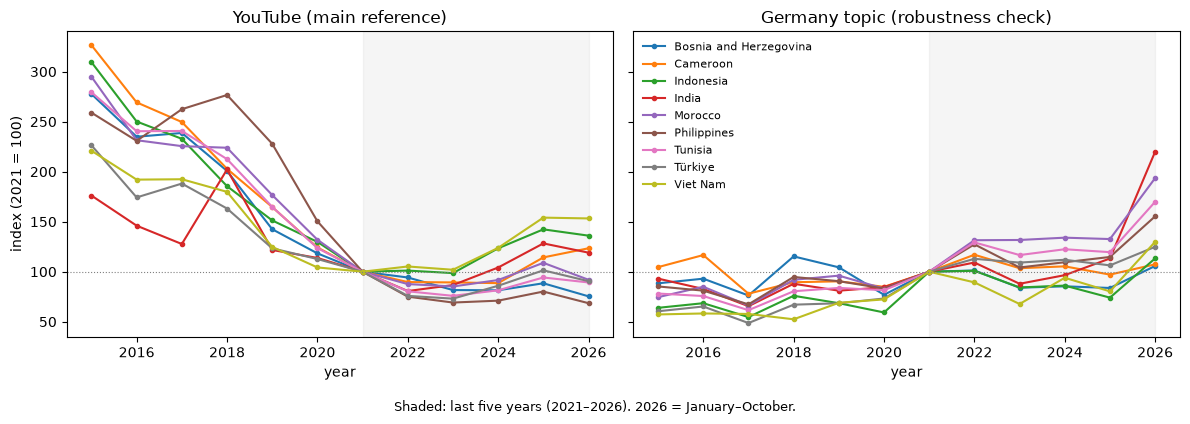

,YouTube 2015→2021 (%),YouTube 2021→2026 (%),Germany 2015→2021 (%),Germany 2021→2026 (%)
Bosnia and Herzegovina,-64.0,-25.0,13.0,6.0
Cameroon,-69.0,23.0,-4.0,7.0
Indonesia,-68.0,36.0,57.0,13.0
India,-43.0,19.0,7.0,120.0
Morocco,-66.0,-8.0,34.0,94.0
Philippines,-61.0,-31.0,17.0,55.0
Tunisia,-64.0,-11.0,28.0,70.0
Türkiye,-56.0,-9.0,65.0,25.0
Viet Nam,-55.0,53.0,75.0,30.0


In [3]:
yearly = monthly.groupby(monthly.index.year).mean()
yearly.index.name = "year"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (ref, title) in zip(axes, [("ref_topic_youtube", "YouTube (main reference)"),
                                    ("ref_topic_germany", "Germany topic (robustness check)")]):
    for code in done:
        s = yearly[(code, ref)]
        ax.plot(s.index, s / s.loc[2021] * 100, marker="o", ms=3, label=CODES[code])
    ax.axhline(100, color="grey", lw=0.8, ls=":")
    ax.axvspan(2021, 2026, color="grey", alpha=0.08)
    ax.set_title(title)
    ax.set_xlabel("year")
axes[0].set_ylabel("index (2021 = 100)")
axes[1].legend(frameon=False, fontsize=8)
fig.text(0.5, -0.04, "Shaded: last five years (2021–2026). 2026 = January–October.", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "04b_reference_stability.png", dpi=150, bbox_inches="tight")
plt.show()

stability = pd.DataFrame({
    "YouTube 2015→2021 (%)": {CODES[c]: (yearly.loc[2021, (c, "ref_topic_youtube")] / yearly.loc[2015, (c, "ref_topic_youtube")] - 1) * 100 for c in done},
    "YouTube 2021→2026 (%)": {CODES[c]: (yearly.loc[2026, (c, "ref_topic_youtube")] / yearly.loc[2021, (c, "ref_topic_youtube")] - 1) * 100 for c in done},
    "Germany 2015→2021 (%)": {CODES[c]: (yearly.loc[2021, (c, "ref_topic_germany")] / yearly.loc[2015, (c, "ref_topic_germany")] - 1) * 100 for c in done},
    "Germany 2021→2026 (%)": {CODES[c]: (yearly.loc[2026, (c, "ref_topic_germany")] / yearly.loc[2021, (c, "ref_topic_germany")] - 1) * 100 for c in done},
}).round(0)
stability

**What we see.** YouTube searches **fell by 43–68%** from 2015 to 2021 in every country (people open the app instead of searching for it). Since 2021 the changes are smaller, which matches Prof. Gunes's view of the last five years. The Germany topic **grew** in every country.

**Consequence.** Over 2015–2021, a share based on YouTube goes up partly *because YouTube went down*. So:
- **Comparing countries in the same year** → fine with both references.
- **Trends over time** → use the period since 2021, or read them together with the Germany topic.

## 4. Make the keywords comparable

For each country and theme we divide the keyword by the reference **of the same country and month**:

- `per_100k_youtube` = keyword / YouTube × 100,000
- `per_1000_germany` = keyword / Germany topic × 1,000

(The multipliers only make the numbers easier to read.)

In [4]:
rows = []
for code in done:
    for theme in THEMES:
        if (code, theme) not in yearly.columns:
            continue
        for year in yearly.index:
            kw = yearly.loc[year, (code, theme)]
            rows.append({
                "code": code, "country": CODES[code], "theme": theme, "year": year,
                "per_100k_youtube": kw / yearly.loc[year, (code, "ref_topic_youtube")] * 1e5,
                "per_1000_germany": kw / yearly.loc[year, (code, "ref_topic_germany")] * 1e3,
            })
comparable = pd.DataFrame(rows)
comparable.pivot_table(index=["theme", "country"], columns="year", values="per_100k_youtube").round(1)

year                              2015   2016   2017   2018   2019   2020  \
theme    country                                                            
care     Indonesia                 0.0    0.1    0.1    0.1    0.6    0.4   
         Philippines               0.2    2.0    2.9    2.7    3.0    3.7   
         Türkiye                   0.0    0.0    0.0    4.2    3.8    4.1   
         Viet Nam                  7.7   10.7   13.6   13.0   18.8   20.7   
training Cameroon                  0.0    0.0    0.0    0.0   21.6   83.9   
         India                     0.0    0.0    0.0    0.0    0.0    0.0   
         Indonesia                 0.0    0.0    0.1    1.1    3.6    3.1   
         Morocco                   0.5    0.8    3.8   14.2   70.6   86.0   
         Tunisia                   0.0    0.0    0.0    0.0   45.6   91.2   
         Türkiye                   0.0    0.0    0.0    0.0    0.0    0.0   
         Viet Nam                  0.6    2.6    3.6    6.0   17.1   18.2   
work     Bosnia and Herzegovina  109.2  172.2  167.0  182.1  191.5  117.2   
         Cameroon                 31.3   93.2   83.0  125.9  180.0  118.6   
         India                    27.6   24.5   28.4   16.7   27.9   26.5   
         Indonesia                 4.0    4.1    4.1    5.4    7.6   11.6   
         Morocco                  27.2   28.0   33.0   42.0   71.2   40.4   
         Philippines               2.7    3.0    2.5    2.6    2.5    2.8   
         Tunisia                  47.5   59.4   59.5   66.9  105.8   79.1   
         Türkiye                   2.5    3.1    3.6   10.4   16.5   14.8   
         Viet Nam                  0.0    0.5    3.4    1.7    3.8    2.3   

year                              2021   2022   2023   2024   2025   2026  
theme    country                                                           
care     Indonesia                 1.0    2.1    3.0    2.5    2.8    4.5  
         Philippines               6.1    9.0    9.9   10.6   10.7   18.1  
         Türkiye                   8.5   12.5   13.0    7.1    3.6    2.7  
         Viet Nam                 23.5   28.8   35.8   28.9   21.0   24.0  
training Cameroon                 96.3  465.5  545.7  607.1  499.6  810.3  
         India                     0.4    3.5    5.9    6.5    7.4   11.1  
         Indonesia                 6.3    7.4    9.7   12.9   15.0   20.2  
         Morocco                 151.0  273.3  411.1  448.4  373.9  425.2  
         Tunisia                 172.9  317.8  465.5  600.1  422.7  424.4  
         Türkiye                   0.8    3.0    3.4    3.3    1.9    2.8  
         Viet Nam                 34.8   30.0   70.9   50.7   31.1   28.5  
work     Bosnia and Herzegovina   95.3   88.4   51.3    6.7   10.7    0.0  
         Cameroon                217.2  345.9  395.6  377.6  235.4  271.3  
         India                    34.5   50.3   47.0   40.0   35.6   37.2  
         Indonesia                18.2   20.6   21.5   16.1   15.2   19.2  
         Morocco                  38.7  109.3  116.0   88.4   68.4   44.7  
         Philippines               4.5    6.7    8.2    8.4    9.2   13.4  
         Tunisia                 119.2  261.0  270.0  268.0  147.6  111.6  
         Türkiye                  25.7   49.9   57.8   34.8   17.5   13.0  
         Viet Nam                  3.3    6.8   15.3   11.8    7.2    7.8

## 5. Which countries search most? (main result)

Left: YouTube reference (main). Right: Germany topic (check). Each line is one country.

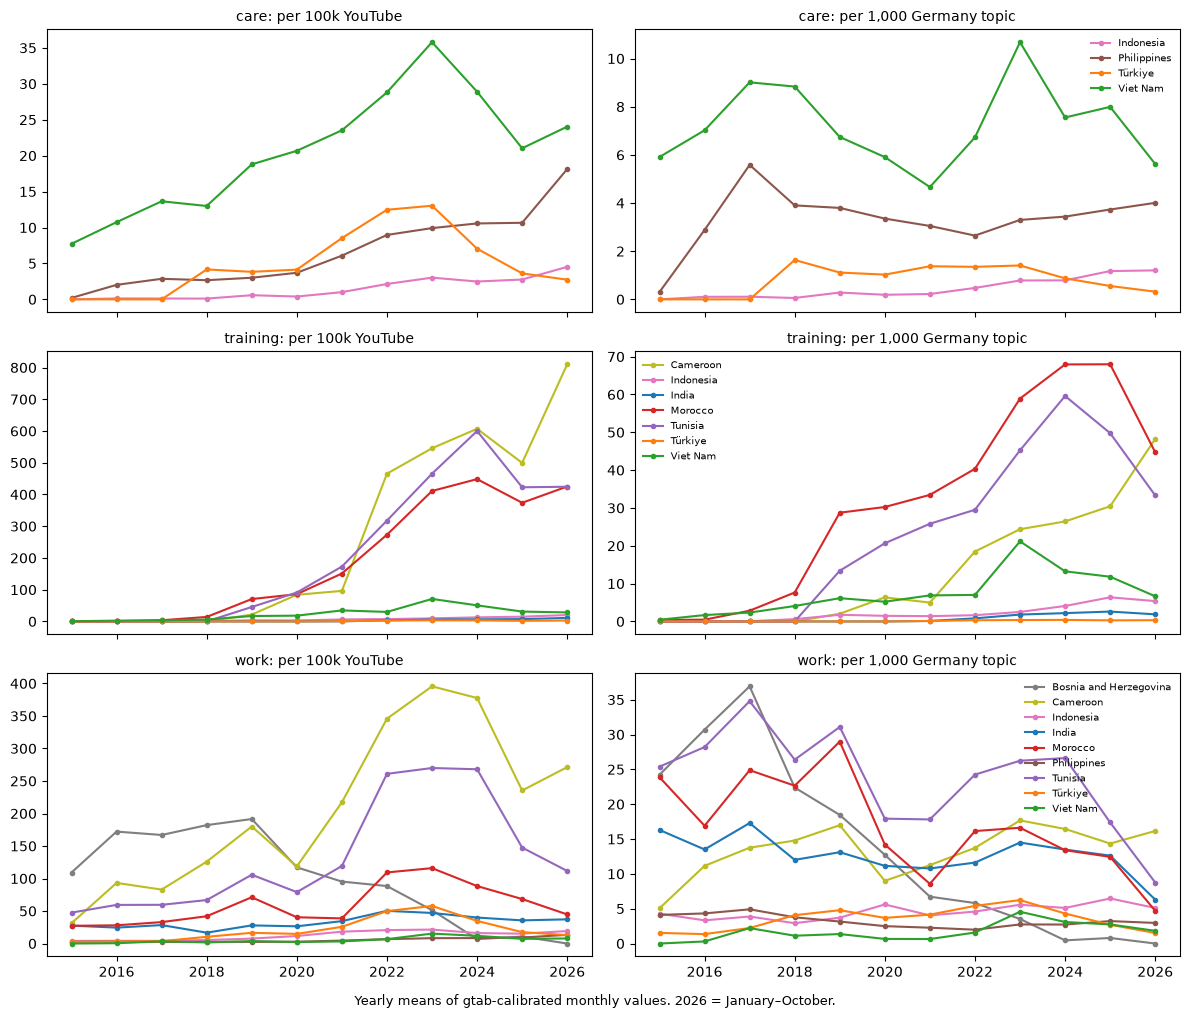

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
colors = {c: f"C{i}" for i, c in enumerate(CODES)}
for row, theme in enumerate(THEMES):
    for col, (value, label) in enumerate([("per_100k_youtube", "per 100k YouTube"),
                                          ("per_1000_germany", "per 1,000 Germany topic")]):
        ax = axes[row, col]
        part = comparable[comparable["theme"] == theme]
        for code, s in part.groupby("code"):
            ax.plot(s["year"], s[value], marker="o", ms=3, color=colors[code], label=CODES[code])
        ax.set_title(f"{theme}: {label}", fontsize=10)
        if col == 1:
            ax.legend(frameon=False, fontsize=7)
fig.text(0.5, -0.01, "Yearly means of gtab-calibrated monthly values. 2026 = January–October.", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "04b_rq1_countries_by_theme.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Ranking in the last full year
last = comparable[comparable["year"] == LAST_FULL_YEAR]
for theme in THEMES:
    t = (last[last["theme"] == theme]
         .set_index("country")[["per_100k_youtube", "per_1000_germany"]]
         .sort_values("per_100k_youtube", ascending=False).round(2))
    print(f"\n{theme.upper()} ({LAST_FULL_YEAR})")
    print(t.to_string())


CARE (2025)
             per_100k_youtube  per_1000_germany
country                                        
Viet Nam                21.03              7.99
Philippines             10.66              3.73
Türkiye                  3.61              0.56
Indonesia                2.76              1.17

TRAINING (2025)
           per_100k_youtube  per_1000_germany
country                                      
Cameroon             499.56             30.45
Tunisia              422.74             49.77
Morocco              373.89             67.98
Viet Nam              31.11             11.83
Indonesia             14.98              6.38
India                  7.37              2.61
Türkiye                1.87              0.29

WORK (2025)
                        per_100k_youtube  per_1000_germany
country                                                   
Cameroon                          235.40             14.35
Tunisia                           147.56             17.37
Morocco            

## 6. Do both references give the same ranking?

We use the **Spearman rank correlation** between the two rankings (1 = same order, 0 = no link). We compute it with `rank().corr()`, because scipy is not installed.

With only 4–5 countries per theme this is a **descriptive** check, not a statistical test.

In [7]:
agreement = []
for theme in THEMES:
    for year in [2019, 2022, LAST_FULL_YEAR]:
        s = comparable[(comparable["theme"] == theme) & (comparable["year"] == year)]
        s = s[(s["per_100k_youtube"] > 0) | (s["per_1000_germany"] > 0)]
        if len(s) >= 3:
            rho = s["per_100k_youtube"].rank().corr(s["per_1000_germany"].rank())
            agreement.append({"theme": theme, "year": year, "countries": len(s), "spearman": round(rho, 2)})
agreement = pd.DataFrame(agreement)
agreement.pivot(index="theme", columns="year", values="spearman")

year,2019,2022,2025
theme,,,
care,0.80,0.80,0.80
training,0.90,0.86,0.86
work,0.85,0.92,0.78


## 7. Findings (all 9 countries)

1. **Care** (4 countries with a care keyword): Viet Nam has the highest interest, then the Philippines; Türkiye and Indonesia are lower. Both references give almost the same order (Spearman 0.8 in 2019, 2022 and 2025).
2. **Training:** Cameroon, Tunisia and Morocco are far above the others, then Viet Nam > Indonesia > India > Türkiye. The order is very similar with both references (0.86–0.90).
3. **Work:** Cameroon, Tunisia, Morocco and India are highest; Viet Nam, the Philippines and Bosnia lowest. Both references agree well (0.78–0.92).
4. **Important caution for Morocco, Tunisia and Cameroon:** their keywords are **broader** (*ausbildung* alone, *visa allemagne*, which also includes tourist visas) than the multi-word keywords of the other countries. A broader word catches more searches. So part of their high values comes from **the keyword, not only from more interest**. Compare these three mainly **with each other**.
5. **Answer to RQ1:** with gtab + a reference search, we can compare countries in a **robust** way: the country ranking hardly changes when we switch the reference (YouTube vs. Germany topic). Comparisons **over time** need care, because YouTube searches fell 43–69% from 2015 to 2021.

### Limitations
- **YouTube is not perfectly stable** (−43% to −69% from 2015 to 2021). It works best for the last five years, as Prof. Gunes noted.
- **The Germany topic is not independent:** it contains our keywords, so it moves partly *with* them.
- **Different keywords per country:** the share also depends on how broad the chosen word is (strongest for MA, TN, CM). We compare *the best available keyword* in each country, not identical searches.
- **gtab uncertainty:** each value has a range (`max_ratio_lo`–`max_ratio_hi`); small values (e.g. Türkiye training) are the least precise. Several series have many zero months before 2021 (e.g. Cameroon training: 75 of 142 months).
- **Small number of countries:** rank correlations with 4–9 countries are only descriptive.
- Google changed its data collection in **January 2016 and January 2022**.


## 8. Save

In [8]:
comparable.to_csv(PROCESSED / "rq1_comparable_yearly.csv", index=False)
stability.to_csv(PROCESSED / "rq1_reference_stability.csv")
agreement.to_csv(PROCESSED / "rq1_rank_agreement.csv", index=False)
print("Saved to", PROCESSED.resolve())

Saved to C:\Users\Tayami\Downloads\F26_MDSSB-CAP-01_Capstone Project\data\processed
